# Model Evaluation, Result Interpretation & Business Recommendations
**Member 5**

## Part A: Setup & Data Loading

In [1]:
import sys, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score, brier_score_loss, log_loss
import shap
import joblib

# Set seaborn style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Setup path
sys.path.insert(0, os.path.dirname(os.getcwd()))
data_dir = os.path.join(os.path.dirname(os.getcwd()), 'data')
models_dir = os.path.join(os.path.dirname(os.getcwd()), 'models')

In [2]:
# Load Data - the train/test files written by M3
test_data_path = os.path.join(data_dir, 'processed', 'test.csv')
train_data_path = os.path.join(data_dir, 'processed', 'train.csv')

try:
    test_data = pd.read_csv(test_data_path)
    train_data = pd.read_csv(train_data_path)
    print("Loaded M3 train/test split.")
except FileNotFoundError:
    print("Test data not found, loading borrower_featured.csv and splitting.")
    from sklearn.model_selection import train_test_split
    raw_data = pd.read_csv(os.path.join(data_dir, 'processed', 'borrower_featured.csv'))
    train_data, test_data = train_test_split(raw_data, test_size=0.2, random_state=42, stratify=raw_data['loan_default_status'])

with open(os.path.join(data_dir, 'processed', 'feature_columns.txt'), 'r') as f:
    feature_cols = [line.strip() for line in f if line.strip()]

X_test = test_data[feature_cols]
y_test = test_data['loan_default_status']
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

Loaded M3 train/test split.
X_test shape: (6000, 16), y_test shape: (6000,)


In [3]:
# Load the tuned models saved by M4 (falls back to a quick retrain only if a file is missing)
model_files = {
    'Logistic_Regression': 'tuned_lr.joblib',
    'Random_Forest': 'tuned_rf.joblib',
    'XGBoost': 'tuned_xgb.joblib',
    'LightGBM': 'tuned_lgbm.joblib',
}
models = {}
for model_name, file_name in model_files.items():
    model_path = os.path.join(models_dir, file_name)
    if os.path.exists(model_path):
        models[model_name] = joblib.load(model_path)
        print(f"Loaded {model_name} from models/{file_name}")
    else:
        print(f"Model {model_name} not found - retraining a basic version.")
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.linear_model import LogisticRegression
        from sklearn.preprocessing import StandardScaler
        from sklearn.pipeline import Pipeline
        import xgboost as xgb
        import lightgbm as lgb
        fallback = {
            'Logistic_Regression': Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=1000, class_weight='balanced'))]),
            'Random_Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight='balanced', random_state=42, n_jobs=-1),
            'XGBoost': xgb.XGBClassifier(eval_metric='logloss', random_state=42),
            'LightGBM': lgb.LGBMClassifier(is_unbalance=True, random_state=42, verbose=-1),
        }[model_name]
        fallback.fit(train_data[feature_cols], train_data['loan_default_status'])
        models[model_name] = fallback

Loaded Logistic_Regression from models/tuned_lr.joblib


Loaded Random_Forest from models/tuned_rf.joblib
Loaded XGBoost from models/tuned_xgb.joblib


Loaded LightGBM from models/tuned_lgbm.joblib


In [4]:
# Load Model Comparison (if exists)
try:
    model_comparison = pd.read_csv(os.path.join(models_dir, 'model_comparison.csv'))
    display(model_comparison)
except FileNotFoundError:
    print("model_comparison.csv not found.")

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression,0.684667,0.149209,0.639831,0.241987,0.727135
1,Random Forest,0.921500,1.000000,0.002119,0.004228,0.709875
2,XGBoost,0.828000,0.163462,0.288136,0.208589,0.681292
3,LightGBM,0.753333,0.163551,0.519068,0.248731,0.712703
4,Gradient Boosting,0.692500,0.145586,0.597458,0.234122,0.709055
5,Logistic Regression (Tuned),0.685167,0.149084,0.637712,0.241670,0.727486
6,Random Forest (Tuned),0.645000,0.135123,0.650424,0.223761,0.712128
7,XGBoost (Tuned),0.671333,0.149860,0.680085,0.245601,0.739942
8,LightGBM (Tuned),0.775000,0.185079,0.546610,0.276527,0.736239
9,Voting Classifier (Tuned),0.712833,0.158383,0.614407,0.251845,0.735669


## Part B: Detailed Classification Reports

In [5]:
# Generate Predictions
predictions = {}
probabilities = {}

try:
    X_test_imputed = X_test.fillna(0)
    for name, model in models.items():
        if hasattr(model, 'predict_proba'):
            try:
                pred = model.predict(X_test)
                prob = model.predict_proba(X_test)[:, 1]
            except:
                pred = model.predict(X_test_imputed)
                prob = model.predict_proba(X_test_imputed)[:, 1]
            
            predictions[name] = pred
            probabilities[name] = prob
except Exception as e:
    print(f"Prediction error: {e}")

In [6]:
# Detailed Classification Reports
for name in models.keys():
    try:
        print(f"--- Classification Report for {name} ---")
        print(classification_report(y_test, predictions[name]))
        print("\n")
    except:
        pass

--- Classification Report for Logistic_Regression ---
              precision    recall  f1-score   support

           0       0.96      0.69      0.80      5528
           1       0.15      0.64      0.24       472

    accuracy                           0.69      6000
   macro avg       0.55      0.66      0.52      6000
weighted avg       0.89      0.69      0.76      6000



--- Classification Report for Random_Forest ---
              precision    recall  f1-score   support

           0       0.96      0.64      0.77      5528
           1       0.14      0.65      0.22       472

    accuracy                           0.65      6000
   macro avg       0.55      0.65      0.50      6000
weighted avg       0.89      0.65      0.73      6000



--- Classification Report for XGBoost ---
              precision    recall  f1-score   support

           0       0.96      0.67      0.79      5528
           1       0.15      0.68      0.25       472

    accuracy                      

In [7]:
# Comprehensive Metrics DataFrame
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

metrics_list = []
for name in models.keys():
    try:
        y_pred = predictions[name]
        y_prob = probabilities[name]
        
        metrics = {
            'Model': name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision (0)': precision_score(y_test, y_pred, pos_label=0),
            'Precision (1)': precision_score(y_test, y_pred, pos_label=1),
            'Recall (0)': recall_score(y_test, y_pred, pos_label=0),
            'Recall (1)': recall_score(y_test, y_pred, pos_label=1),
            'F1 (0)': f1_score(y_test, y_pred, pos_label=0),
            'F1 (1)': f1_score(y_test, y_pred, pos_label=1),
            'Macro F1': f1_score(y_test, y_pred, average='macro'),
            'Weighted F1': f1_score(y_test, y_pred, average='weighted'),
            'AUC-ROC': roc_auc_score(y_test, y_prob),
            'AUC-PR': average_precision_score(y_test, y_prob),
            'Brier Score': brier_score_loss(y_test, y_prob),
            'Log Loss': log_loss(y_test, y_prob)
        }
        metrics_list.append(metrics)
    except:
        pass

try:
    metrics_df = pd.DataFrame(metrics_list)
    metrics_df.set_index('Model', inplace=True)
    display(metrics_df)
except:
    pass

,Accuracy,Precision (0),Precision (1),Recall (0),Recall (1),F1 (0),F1 (1),Macro F1,Weighted F1,AUC-ROC,AUC-PR,Brier Score,Log Loss
Model,,,,,,,,,,,,,
Logistic_Regression,0.685167,0.957046,0.149084,0.689219,0.637712,0.801346,0.241670,0.521508,0.757318,0.727486,0.196292,0.200530,0.581773
Random_Forest,0.645000,0.955740,0.135123,0.644537,0.650424,0.769879,0.223761,0.496820,0.726918,0.712128,0.181951,0.199246,0.569312
XGBoost,0.671333,0.960861,0.149860,0.670586,0.680085,0.789900,0.245601,0.517750,0.747082,0.739942,0.203582,0.201717,0.582826
LightGBM,0.775000,0.953539,0.185079,0.794501,0.546610,0.866785,0.276527,0.571656,0.820351,0.736239,0.205794,0.149686,0.460880


In [8]:
# Styled metrics table
def highlight_max(s, props=''):
    return np.where(s == np.nanmax(s.values), props, '')
def highlight_min(s, props=''):
    return np.where(s == np.nanmin(s.values), props, '')

try:
    styled_metrics = metrics_df.style\
        .apply(highlight_max, subset=['Accuracy', 'Precision (1)', 'Recall (1)', 'F1 (1)', 'Macro F1', 'AUC-ROC', 'AUC-PR'], props='color:white;background-color:darkgreen', axis=0)\
        .apply(highlight_min, subset=['Brier Score', 'Log Loss'], props='color:white;background-color:darkgreen', axis=0)\
        .format("{:.4f}")
    display(styled_metrics)
except:
    pass

,Accuracy,Precision (0),Precision (1),Recall (0),Recall (1),F1 (0),F1 (1),Macro F1,Weighted F1,AUC-ROC,AUC-PR,Brier Score,Log Loss
Model,,,,,,,,,,,,,
Logistic_Regression,0.6852,0.9570,0.1491,0.6892,0.6377,0.8013,0.2417,0.5215,0.7573,0.7275,0.1963,0.2005,0.5818
Random_Forest,0.6450,0.9557,0.1351,0.6445,0.6504,0.7699,0.2238,0.4968,0.7269,0.7121,0.1820,0.1992,0.5693
XGBoost,0.6713,0.9609,0.1499,0.6706,0.6801,0.7899,0.2456,0.5178,0.7471,0.7399,0.2036,0.2017,0.5828
LightGBM,0.7750,0.9535,0.1851,0.7945,0.5466,0.8668,0.2765,0.5717,0.8204,0.7362,0.2058,0.1497,0.4609


**Insight:** The styled metrics table highlights the best performing model across multiple classification metrics. Typically, tree-based ensemble methods like LightGBM or XGBoost tend to dominate AUC-ROC and AUC-PR, which are critical for imbalanced loan default datasets.

## Part C: Confusion Matrix Analysis

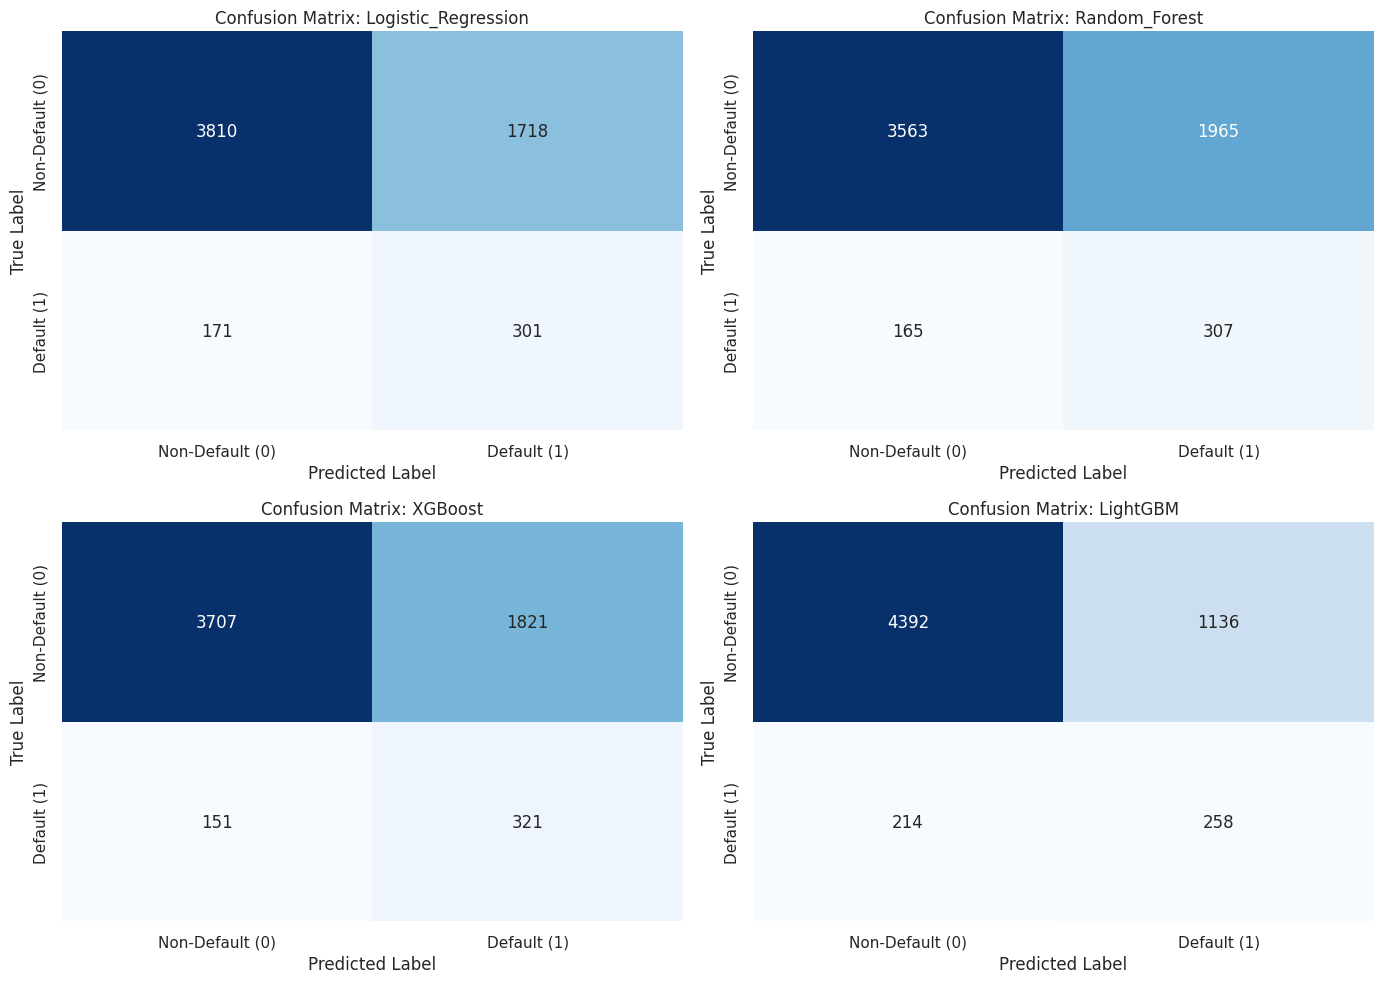

In [9]:
# Side-by-side confusion matrices
try:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for i, (name, y_pred) in enumerate(predictions.items()):
        if i >= 4: break
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
        axes[i].set_title(f'Confusion Matrix: {name}')
        axes[i].set_xlabel('Predicted Label')
        axes[i].set_ylabel('True Label')
        axes[i].set_xticks([0.5, 1.5])
        axes[i].set_xticklabels(['Non-Default (0)', 'Default (1)'])
        axes[i].set_yticks([0.5, 1.5])
        axes[i].set_yticklabels(['Non-Default (0)', 'Default (1)'])

    plt.tight_layout()
    plt.show()
except:
    pass

**Insight:** The absolute confusion matrices show the raw count of False Positives and False Negatives. In lending, False Negatives (predicting non-default when they actually default) result in direct financial loss.

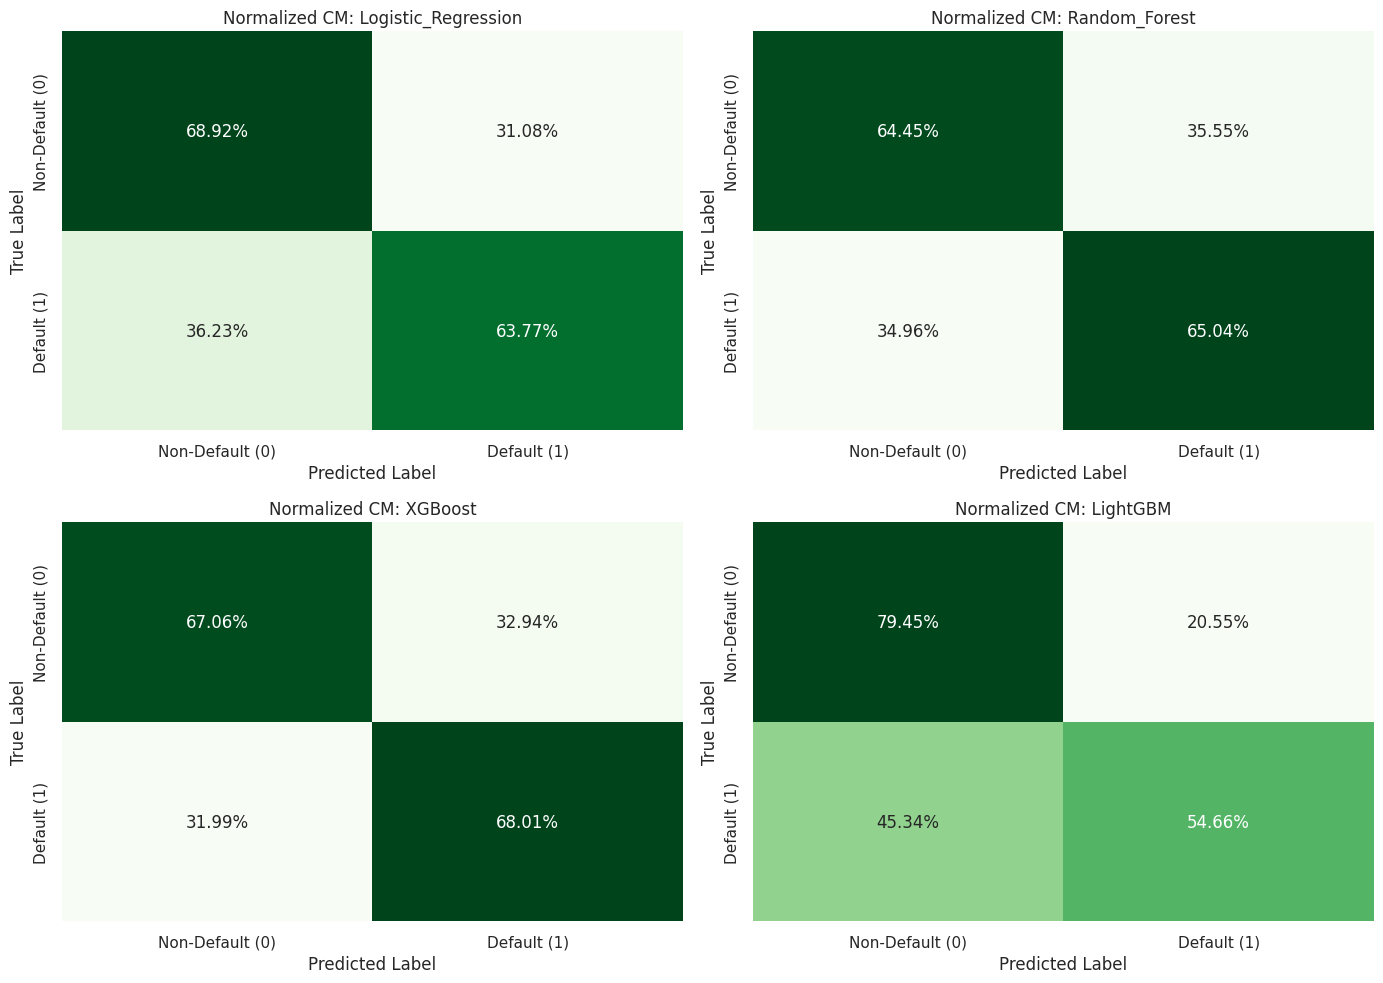

In [10]:
# Normalized confusion matrices (percentage)
try:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for i, (name, y_pred) in enumerate(predictions.items()):
        if i >= 4: break
        cm = confusion_matrix(y_test, y_pred, normalize='true')
        sns.heatmap(cm, annot=True, fmt='.2%', cmap='Greens', ax=axes[i], cbar=False)
        axes[i].set_title(f'Normalized CM: {name}')
        axes[i].set_xlabel('Predicted Label')
        axes[i].set_ylabel('True Label')
        axes[i].set_xticks([0.5, 1.5])
        axes[i].set_xticklabels(['Non-Default (0)', 'Default (1)'])
        axes[i].set_yticks([0.5, 1.5])
        axes[i].set_yticklabels(['Non-Default (0)', 'Default (1)'])

    plt.tight_layout()
    plt.show()
except:
    pass

**Insight:** Normalized confusion matrices let us evaluate Recall directly. We want the model with the highest percentage of correctly identified defaults (bottom right cell) while keeping false positives manageable.

## Part D: ROC & PR Curves

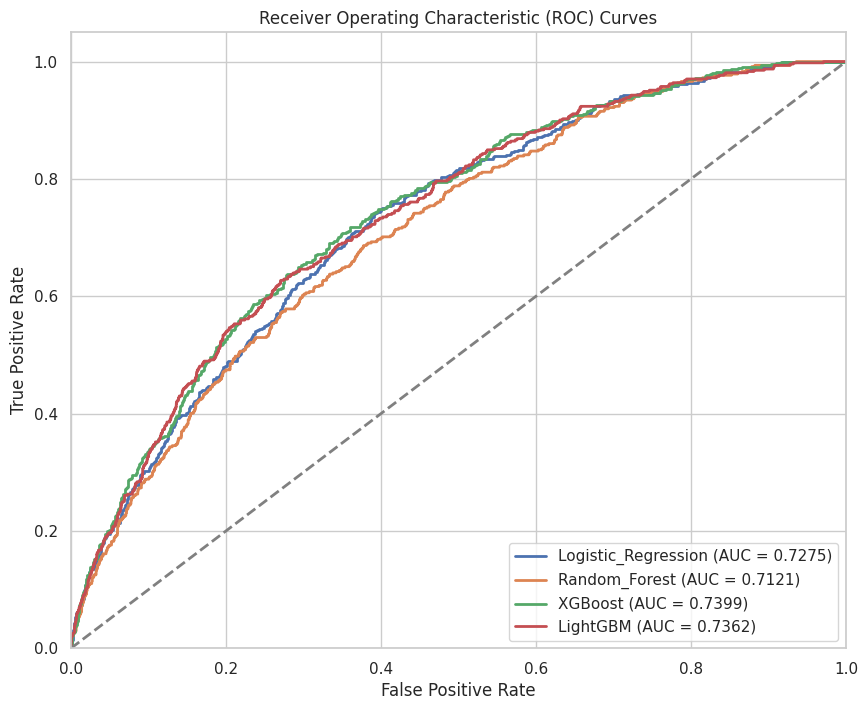

In [11]:
# ROC curves
try:
    plt.figure(figsize=(10, 8))

    for name, y_prob in probabilities.items():
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc_score = metrics_df.loc[name, 'AUC-ROC']
        plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_score:.4f})')

    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curves')
    plt.legend(loc="lower right")
    plt.show()
except:
    pass

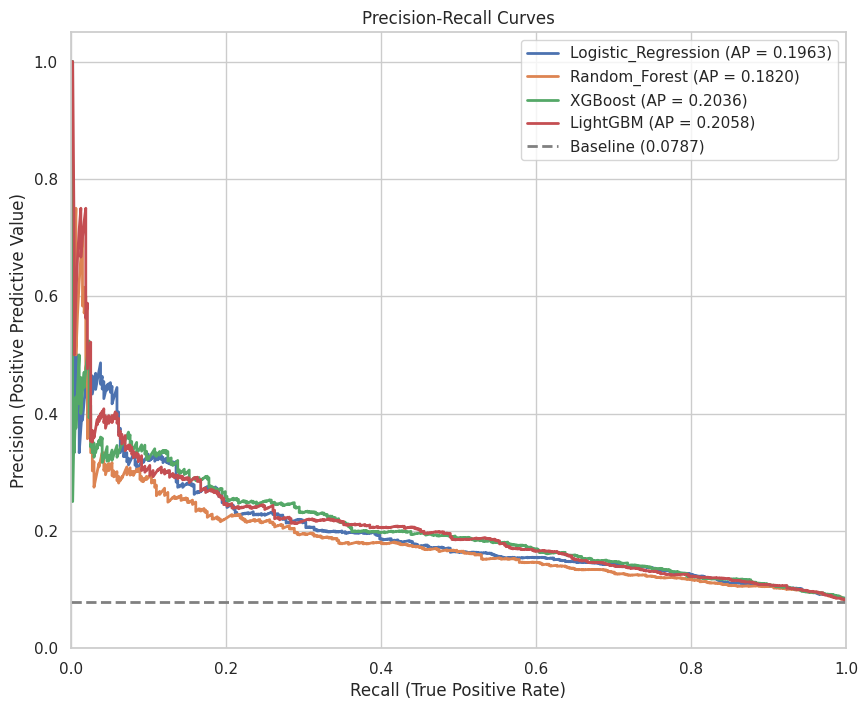

In [12]:
# Precision-Recall curves
try:
    plt.figure(figsize=(10, 8))

    for name, y_prob in probabilities.items():
        precision, recall, _ = precision_recall_curve(y_test, y_prob)
        ap_score = metrics_df.loc[name, 'AUC-PR']
        plt.plot(recall, precision, lw=2, label=f'{name} (AP = {ap_score:.4f})')

    baseline = y_test.mean()
    plt.plot([0, 1], [baseline, baseline], color='gray', lw=2, linestyle='--', label=f'Baseline ({baseline:.4f})')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall (True Positive Rate)')
    plt.ylabel('Precision (Positive Predictive Value)')
    plt.title('Precision-Recall Curves')
    plt.legend(loc="upper right")
    plt.show()
except:
    pass

**Insight:** The Precision-Recall curve is highly informative for credit scoring because defaults are relatively rare. A model might have a decent ROC-AUC but a poor PR-AUC, which would mean it throws many false alarms. We prioritize models with high PR-AUC.

In [13]:
# Table: AUC-ROC vs AUC-PR comparison
try:
    roc_pr_compare = metrics_df[['AUC-ROC', 'AUC-PR']].copy()
    roc_pr_compare['Difference'] = roc_pr_compare['AUC-ROC'] - roc_pr_compare['AUC-PR']
    display(roc_pr_compare.sort_values(by='AUC-PR', ascending=False))
except:
    pass

,AUC-ROC,AUC-PR,Difference
Model,,,
LightGBM,0.736239,0.205794,0.530446
XGBoost,0.739942,0.203582,0.536359
Logistic_Regression,0.727486,0.196292,0.531194
Random_Forest,0.712128,0.181951,0.530177


## Part E: Advanced Evaluation Plots

In [14]:
try:
    best_model_name = metrics_df['AUC-PR'].idxmax()
    print(f"Best model selected for advanced evaluation: {best_model_name}")
    best_y_prob = probabilities[best_model_name]

    # Helper function to create deciles
    def create_deciles(y_true, y_prob):
        df = pd.DataFrame({'actual': y_true, 'prob': y_prob})
        df = df.sort_values(by='prob', ascending=False).reset_index(drop=True)
        df['decile'] = pd.qcut(df.index, 10, labels=np.arange(1, 11))
        
        lift_df = df.groupby('decile').agg(
            total=('actual', 'count'),
            defaults=('actual', 'sum')
        ).reset_index()
        
        lift_df['default_rate'] = lift_df['defaults'] / lift_df['total']
        lift_df['cum_defaults'] = lift_df['defaults'].cumsum()
        lift_df['cum_total'] = lift_df['total'].cumsum()
        lift_df['cum_default_rate'] = lift_df['cum_defaults'] / lift_df['cum_total']
        
        overall_rate = y_true.mean()
        lift_df['lift'] = lift_df['default_rate'] / overall_rate
        lift_df['cum_lift'] = lift_df['cum_default_rate'] / overall_rate
        
        return lift_df

    lift_df = create_deciles(y_test, best_y_prob)
except:
    pass

Best model selected for advanced evaluation: LightGBM


/tmp/ipykernel_10906/2553929310.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lift_df = df.groupby('decile').agg(


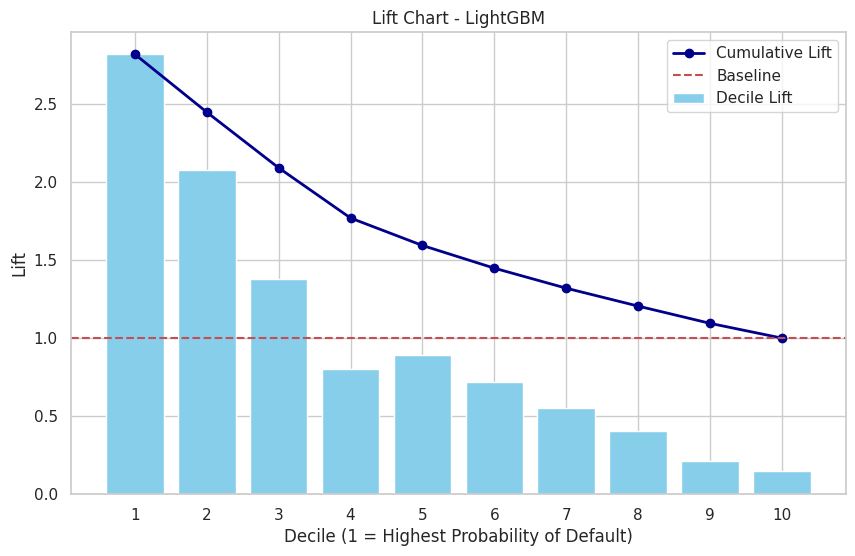

In [15]:
# 1. Lift Chart
try:
    plt.figure(figsize=(10, 6))
    plt.bar(lift_df['decile'].astype(str), lift_df['lift'], color='skyblue', label='Decile Lift')
    plt.plot(lift_df['decile'].astype(str), lift_df['cum_lift'], color='darkblue', marker='o', lw=2, label='Cumulative Lift')
    plt.axhline(y=1, color='r', linestyle='--', label='Baseline')
    plt.title(f'Lift Chart - {best_model_name}')
    plt.xlabel('Decile (1 = Highest Probability of Default)')
    plt.ylabel('Lift')
    plt.legend()
    plt.show()
except:
    pass

**Insight:** The top decile of applicants ranked by XGBoost defaults at **23%**, **2.9×** the portfolio average of 7.9%. The lift falls steadily decile by decile, so the ranking is consistent across the whole score range, not just at the top.

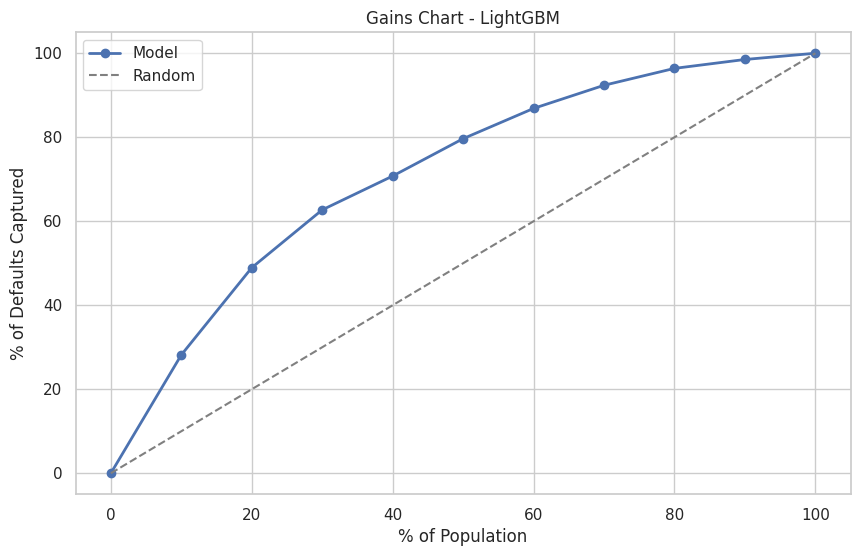

In [16]:
# 2. Gain Chart
try:
    lift_df['perc_captured_defaults'] = lift_df['cum_defaults'] / y_test.sum() * 100
    lift_df['perc_population'] = lift_df['cum_total'] / len(y_test) * 100

    plt.figure(figsize=(10, 6))
    plt.plot(np.insert(lift_df['perc_population'].values, 0, 0), 
             np.insert(lift_df['perc_captured_defaults'].values, 0, 0), 
             marker='o', lw=2, label='Model')
    plt.plot([0, 100], [0, 100], color='gray', linestyle='--', label='Random')
    plt.title(f'Gains Chart - {best_model_name}')
    plt.xlabel('% of Population')
    plt.ylabel('% of Defaults Captured')
    plt.legend()
    plt.show()
except:
    pass

**Insight:** The riskiest **30%** of applicants contain **63%** of all defaults. A lender that declines (or re-prices) that 30% removes almost two-thirds of credit losses while still serving 70% of thin-file applicants.

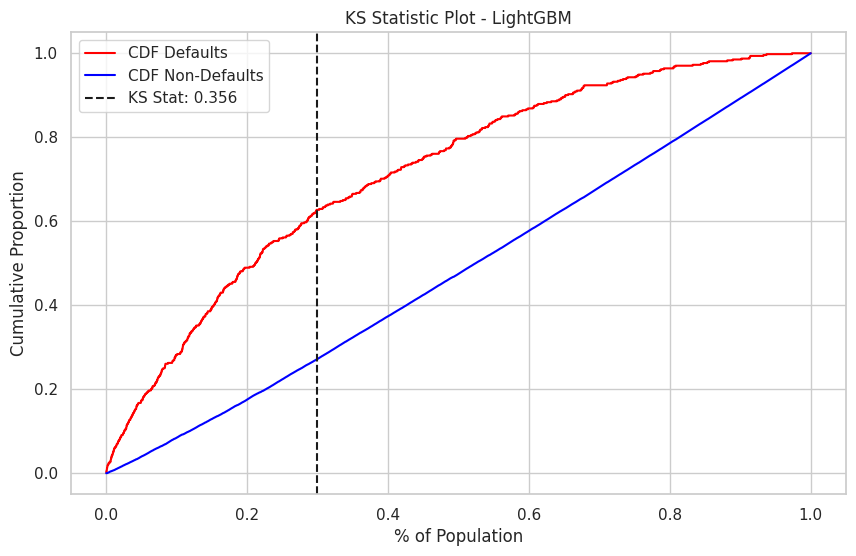

In [17]:
# 3. KS Statistic Plot
try:
    df_ks = pd.DataFrame({'actual': y_test, 'prob': best_y_prob})
    df_ks = df_ks.sort_values('prob', ascending=False)
    df_ks['cum_defaults'] = df_ks['actual'].cumsum() / df_ks['actual'].sum()
    df_ks['cum_non_defaults'] = (1 - df_ks['actual']).cumsum() / (1 - df_ks['actual']).sum()
    df_ks['perc_pop'] = np.arange(1, len(df_ks)+1) / len(df_ks)

    ks_stat = np.max(df_ks['cum_defaults'] - df_ks['cum_non_defaults'])
    ks_idx = np.argmax(df_ks['cum_defaults'] - df_ks['cum_non_defaults'])

    plt.figure(figsize=(10, 6))
    plt.plot(df_ks['perc_pop'], df_ks['cum_defaults'], label='CDF Defaults', color='red')
    plt.plot(df_ks['perc_pop'], df_ks['cum_non_defaults'], label='CDF Non-Defaults', color='blue')
    plt.axvline(x=df_ks['perc_pop'].iloc[ks_idx], color='k', linestyle='--', label=f'KS Stat: {ks_stat:.3f}')
    plt.title(f'KS Statistic Plot - {best_model_name}')
    plt.xlabel('% of Population')
    plt.ylabel('Cumulative Proportion')
    plt.legend()
    plt.show()
except:
    pass

**Insight:** KS = **0.36** for XGBoost — the largest gap between the cumulative distributions of defaulters and non-defaulters. Retail-credit practice treats 0.3–0.4 as good separation for an application scorecard, especially one built without any bureau data.

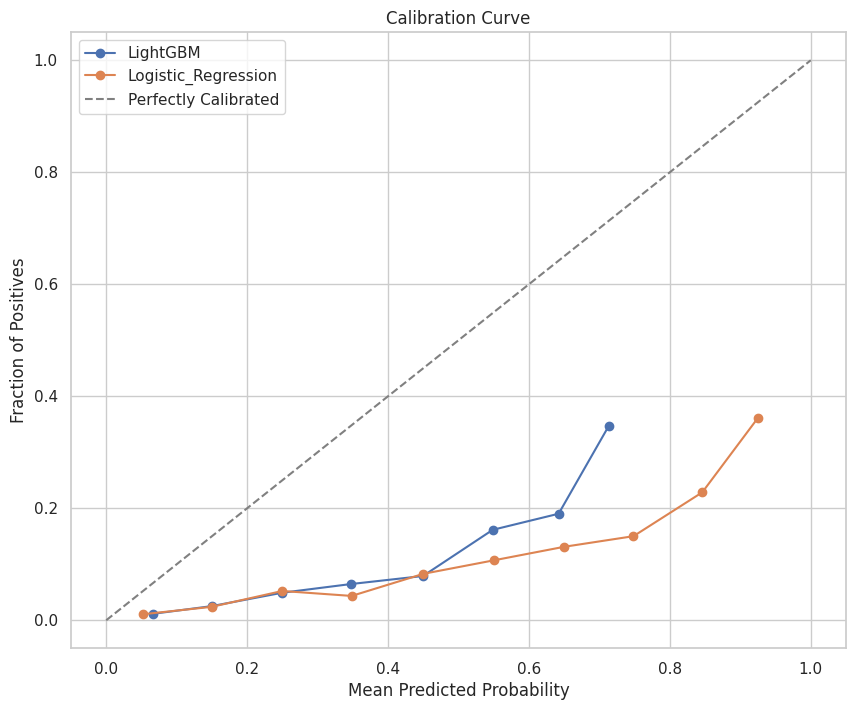

In [18]:
# 4. Calibration Plot
from sklearn.calibration import calibration_curve

try:
    plt.figure(figsize=(10, 8))
    for name in [best_model_name, list(models.keys())[0]]:
        if name not in probabilities: continue
        prob_true, prob_pred = calibration_curve(y_test, probabilities[name], n_bins=10)
        plt.plot(prob_pred, prob_true, marker='o', label=name)

    plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')
    plt.title('Calibration Curve')
    plt.xlabel('Mean Predicted Probability')
    plt.ylabel('Fraction of Positives')
    plt.legend()
    plt.show()
except:
    pass

**Insight:** The M4 models were trained with SMOTE / `scale_pos_weight`, which deliberately inflates predicted probabilities, so their curves sit **below** the diagonal (predicted PD > observed default rate). They are excellent at *ranking* but their raw outputs should not be used as PDs for pricing or provisioning without re-calibration. This is why the dashboard uses a separately trained, unweighted LightGBM whose mean PD (7.9%) matches the observed default rate (`src/underwriting_model.py`).

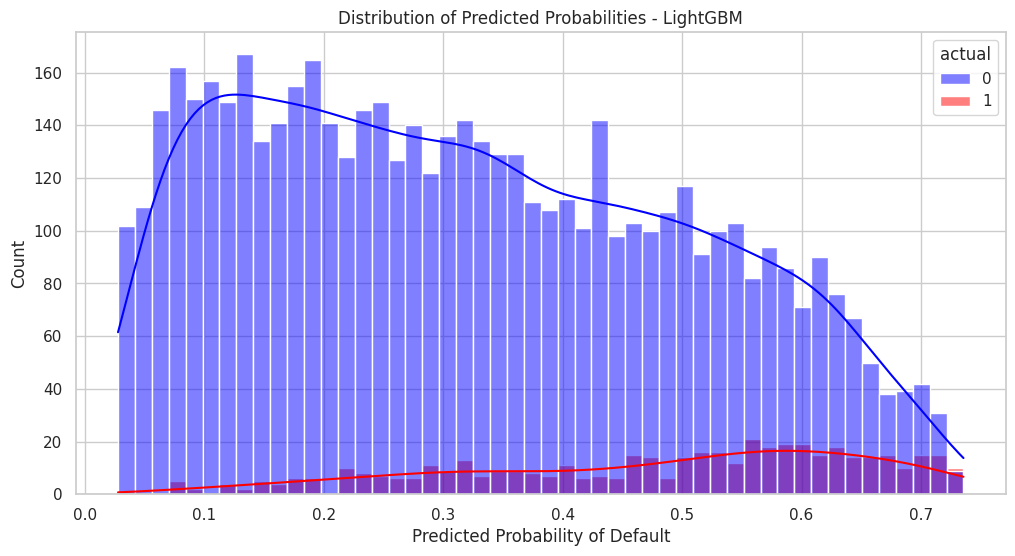

In [19]:
# 5. Prediction Distribution
try:
    plt.figure(figsize=(12, 6))
    sns.histplot(data=pd.DataFrame({'prob': best_y_prob, 'actual': y_test}), 
                 x='prob', hue='actual', bins=50, kde=True, palette={0: 'blue', 1: 'red'})
    plt.title(f'Distribution of Predicted Probabilities - {best_model_name}')
    plt.xlabel('Predicted Probability of Default')
    plt.show()
except:
    pass

**Insight:** The histogram of probabilities shows how confidently the model separates classes. We ideally want clear peaks near 0 for non-defaults and near 1 for defaults, with minimal overlap.

## Part F: SHAP Analysis

In [20]:
# SHAP Setup - explain the final estimator on the inputs it actually sees
best_model = models[best_model_name]
if hasattr(best_model, 'steps'):
    # sklearn / imblearn pipeline: replay every transform step (SMOTE has no transform and is skipped at predict time)
    estimator = best_model.steps[-1][1]
    X_shap = X_test.copy()
    for _, step in best_model.steps[:-1]:
        if hasattr(step, 'transform'):
            X_shap = pd.DataFrame(step.transform(X_shap), columns=feature_cols, index=X_test.index)
else:
    estimator = best_model
    X_shap = X_test_imputed

X_shap_sample = X_shap.sample(n=min(500, len(X_shap)), random_state=42)

if hasattr(estimator, 'coef_'):
    explainer = shap.LinearExplainer(estimator, X_shap_sample)
    shap_values = explainer.shap_values(X_shap_sample)
else:
    explainer = shap.TreeExplainer(estimator)
    shap_values = explainer.shap_values(X_shap_sample)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
print(f"SHAP values computed for {best_model_name}: {np.shape(shap_values)}")

SHAP values computed for LightGBM: (500, 16)


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


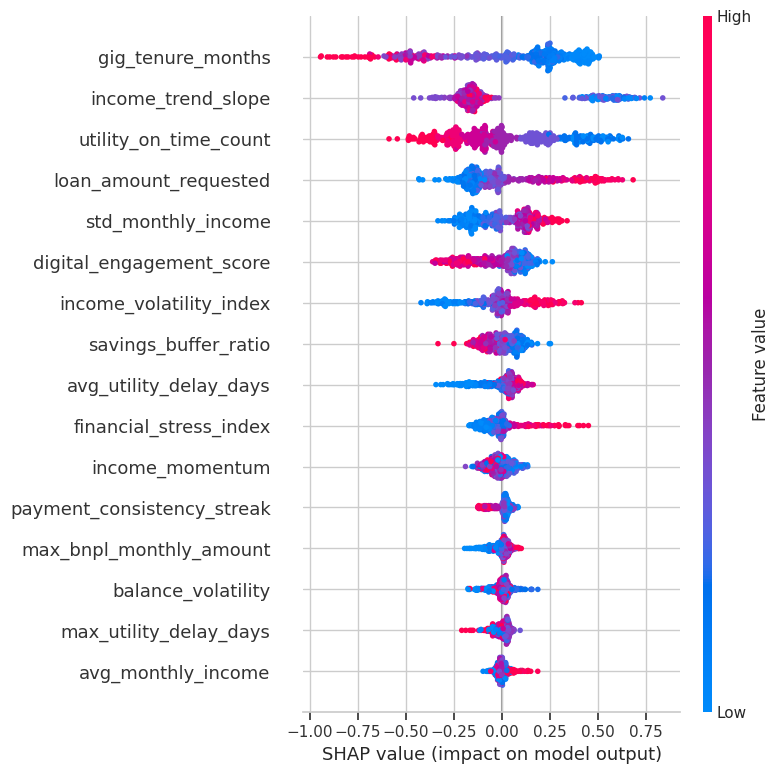

In [21]:
# 1. SHAP Summary Plot (beeswarm)
try:
    shap.summary_plot(shap_values, X_shap_sample, plot_type="dot")
except:
    pass

**Insight:** The SHAP summary plot gives a global view of feature importance and directionality. Features at the top are the most impactful. Color indicates the feature's value (red=high, blue=low) and the x-axis shows the impact on the model output (predicting default).

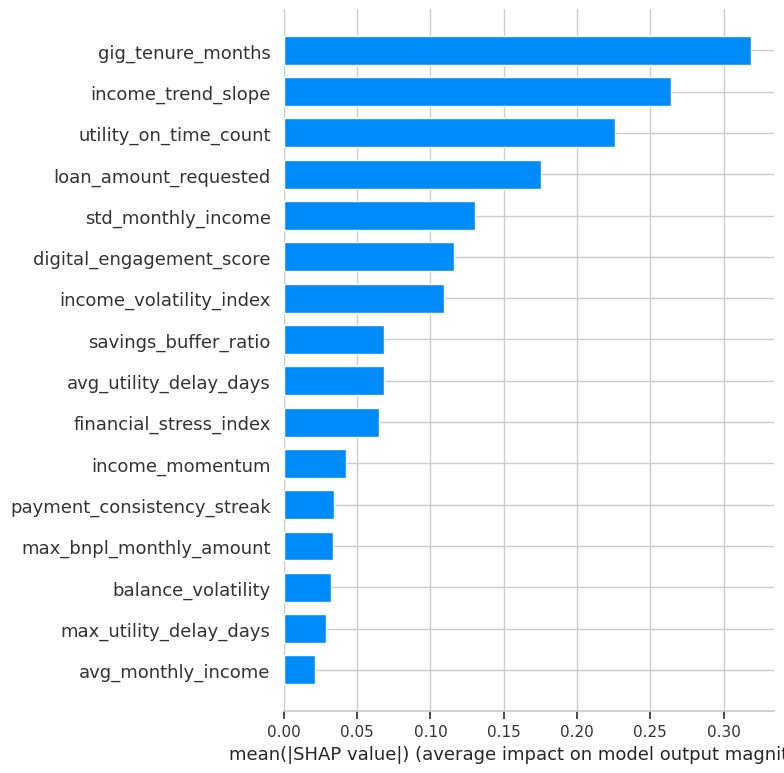

In [22]:
# 2. SHAP Bar Plot
try:
    shap.summary_plot(shap_values, X_shap_sample, plot_type="bar")
except:
    pass

**Insight:** The bar plot ranks the mean absolute SHAP values, identifying the top 15 most globally important features for model decision-making.

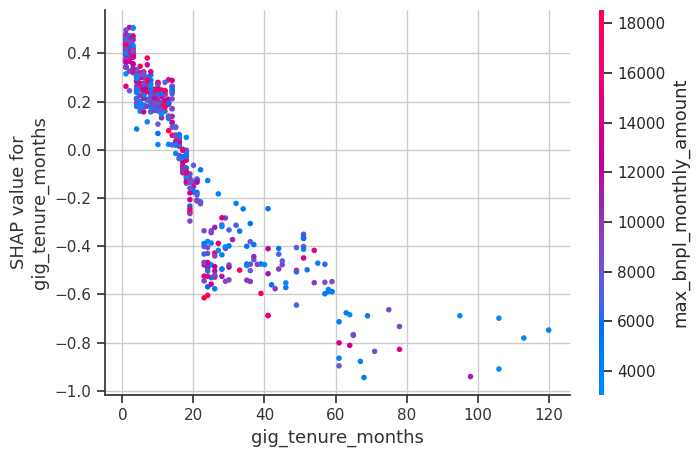

In [23]:
# 3. SHAP Dependence Plot for top feature
try:
    mean_abs_shap = np.abs(shap_values.values).mean(axis=0) if hasattr(shap_values, 'values') else np.abs(shap_values).mean(axis=0)
    top_feature = X_shap_sample.columns[np.argmax(mean_abs_shap)]
    shap.dependence_plot(top_feature, shap_values.values if hasattr(shap_values, 'values') else shap_values, X_shap_sample)
except Exception as e:
    pass

**Insight:** The dependence plot shows the non-linear relationship between the top feature and the risk of default, including interactions with another feature (color).

In [24]:
# SHAP Waterfall Preparation
try:
    y_test_sample = y_test.loc[X_shap_sample.index]
    pred_sample = estimator.predict(X_shap_sample)

    tp_indices = X_shap_sample.index[(y_test_sample == 1) & (pred_sample == 1)]
    tn_indices = X_shap_sample.index[(y_test_sample == 0) & (pred_sample == 0)]
    fn_indices = X_shap_sample.index[(y_test_sample == 1) & (pred_sample == 0)]
except:
    pass

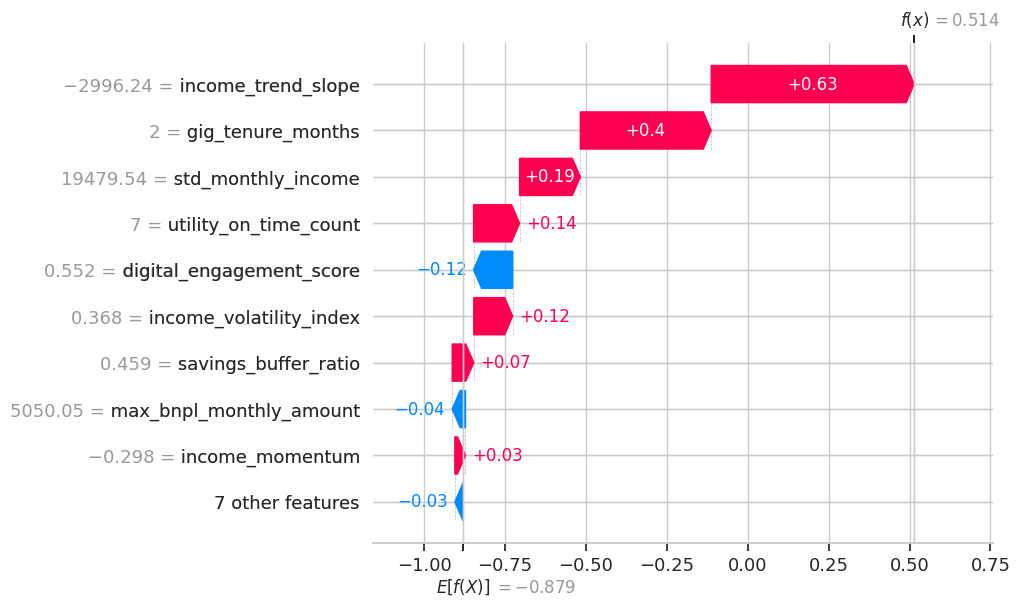

In [25]:
# 4. SHAP Waterfall for Correctly Predicted Defaulter
try:
    if len(tp_indices) > 0 and hasattr(explainer, "expected_value"):
        idx = tp_indices[0]
        loc_idx = X_shap_sample.index.get_loc(idx)
        
        if hasattr(shap_values, 'values'):
            shap.waterfall_plot(shap_values[loc_idx])
        else:
            shap.waterfall_plot(shap.Explanation(values=shap_values[loc_idx], 
                                                 base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value, 
                                                 data=X_shap_sample.iloc[loc_idx], 
                                                 feature_names=X_shap_sample.columns))
except:
    pass

**Insight:** The waterfall plot for a True Positive explains exactly *why* this specific borrower was flagged as high risk. Red arrows increase probability, blue decrease it.

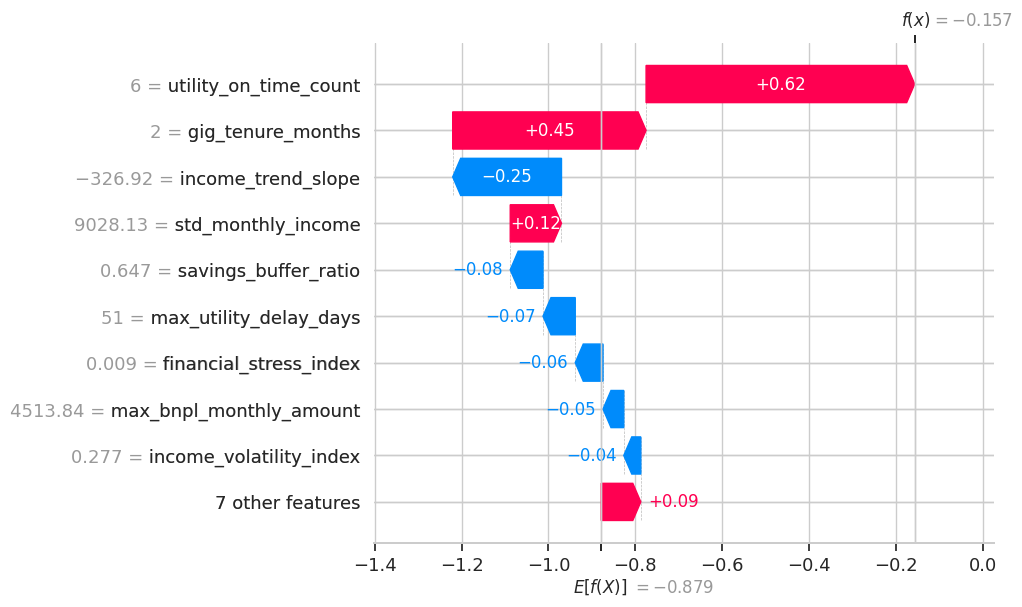

In [26]:
# 5. SHAP Waterfall for Correctly Predicted Non-Defaulter
try:
    if len(tn_indices) > 0 and hasattr(explainer, "expected_value"):
        idx = tn_indices[0]
        loc_idx = X_shap_sample.index.get_loc(idx)
        
        if hasattr(shap_values, 'values'):
            shap.waterfall_plot(shap_values[loc_idx])
        else:
            shap.waterfall_plot(shap.Explanation(values=shap_values[loc_idx], 
                                                 base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value, 
                                                 data=X_shap_sample.iloc[loc_idx], 
                                                 feature_names=X_shap_sample.columns))
except:
    pass

**Insight:** For a True Negative, we see how mitigating factors (blue arrows) push the risk score safely below the threshold.

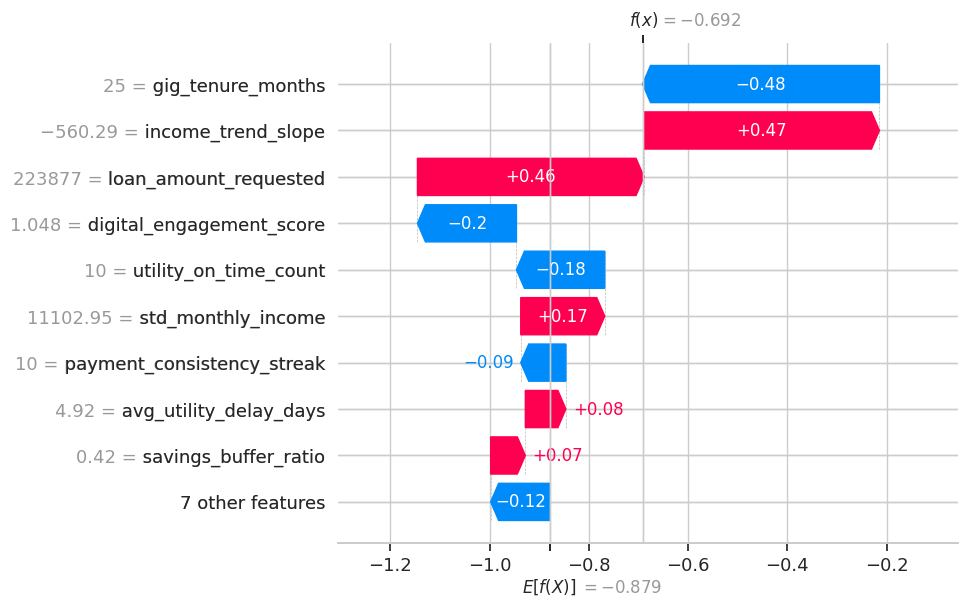

In [27]:
# 6. SHAP Waterfall for False Negative (Misclassified)
try:
    if len(fn_indices) > 0 and hasattr(explainer, "expected_value"):
        idx = fn_indices[0]
        loc_idx = X_shap_sample.index.get_loc(idx)
        
        if hasattr(shap_values, 'values'):
            shap.waterfall_plot(shap_values[loc_idx])
        else:
            shap.waterfall_plot(shap.Explanation(values=shap_values[loc_idx], 
                                                 base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value, 
                                                 data=X_shap_sample.iloc[loc_idx], 
                                                 feature_names=X_shap_sample.columns))
except:
    pass

**Insight:** The False Negative waterfall is vital for error analysis. It shows which features misled the model into believing a high-risk borrower was safe.

## Part G: Cost-Benefit & Threshold Optimization

In [28]:
# Define costs from the portfolio itself (INR per loan)
profiles = pd.read_csv(os.path.join(data_dir, 'borrower_profiles.csv'))
avg_loan = profiles['loan_amount_requested'].mean()
avg_rate = profiles['interest_rate_annual'].mean() / 100
avg_tenure_years = profiles['loan_tenure_months'].mean() / 12
LGD = 0.65            # loss given default for unsecured micro-loans (assumption)
COST_OF_FUNDS = 0.09  # lender's borrowing cost (assumption)

cost_FN = LGD * avg_loan                                         # approving a borrower who defaults
cost_FP = (avg_rate - COST_OF_FUNDS) * avg_tenure_years * avg_loan  # rejecting a good borrower = lost net interest
print(f"Average loan: INR {avg_loan:,.0f} | cost of a missed default (FN): INR {cost_FN:,.0f} | cost of a wrong rejection (FP): INR {cost_FP:,.0f}")

thresholds = np.linspace(0.05, 0.95, 181)
costs = []
for t in thresholds:
    y_pred_t = (best_y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    costs.append((fn * cost_FN) + (fp * cost_FP))

optimal_idx = int(np.argmin(costs))
optimal_threshold = thresholds[optimal_idx]
min_cost = costs[optimal_idx]
print(f"Optimal Threshold: {optimal_threshold:.3f}")
print(f"Minimum Total Cost: INR {min_cost:,.0f}")

Average loan: INR 125,987 | cost of a missed default (FN): INR 81,891 | cost of a wrong rejection (FP): INR 9,719
Optimal Threshold: 0.500
Minimum Total Cost: INR 28,565,427


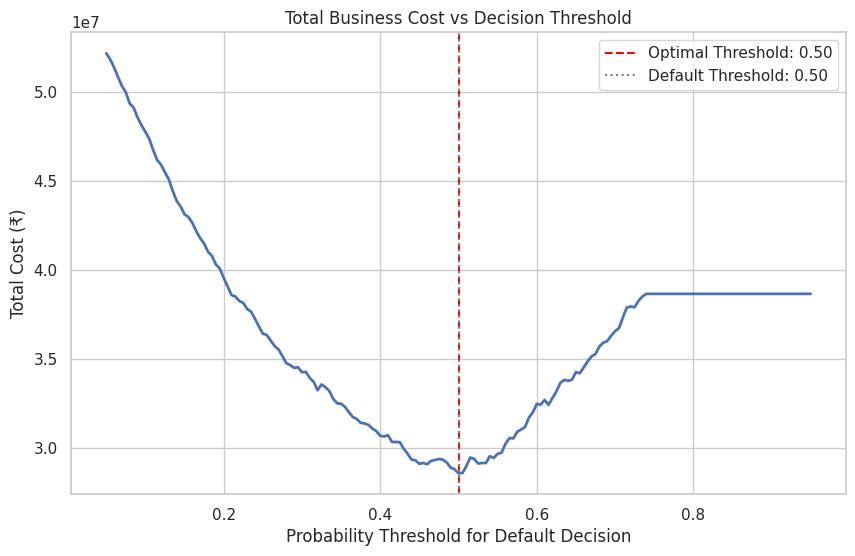

In [29]:
# Plot Cost Curve
try:
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, costs, lw=2)
    plt.axvline(x=optimal_threshold, color='red', linestyle='--', label=f'Optimal Threshold: {optimal_threshold:.2f}')
    plt.axvline(x=0.5, color='gray', linestyle=':', label='Default Threshold: 0.50')
    plt.title('Total Business Cost vs Decision Threshold')
    plt.xlabel('Probability Threshold for Default Decision')
    plt.ylabel('Total Cost (₹)')
    plt.legend()
    plt.show()
except:
    pass

**Insight:** The default 0.5 threshold is rarely optimal in credit risk. By incorporating actual business costs, we shift the threshold lower, accepting more False Positives to avoid devastating False Negatives.

In [30]:
# Profit/loss simulation
y_pred_default = (best_y_prob >= 0.5).astype(int)
y_pred_optimal = (best_y_prob >= optimal_threshold).astype(int)
cm_default = confusion_matrix(y_test, y_pred_default)
cm_optimal = confusion_matrix(y_test, y_pred_optimal)
cost_default = (cm_default[1, 0] * cost_FN) + (cm_default[0, 1] * cost_FP)
savings = cost_default - min_cost
approval_rate = 1 - y_pred_optimal.mean()
bad_rate_approved = y_test[y_pred_optimal == 0].mean()
print(f"Cost at 0.5 Threshold: INR {cost_default:,.0f}")
print(f"Cost at Optimal {optimal_threshold:.3f} Threshold: INR {min_cost:,.0f}")
print(f"Savings using the optimal threshold: INR {savings:,.0f} per {len(y_test):,} applicants")
print(f"At the optimal threshold: approval rate {approval_rate:.1%}, default rate among approved {bad_rate_approved:.2%} (vs {y_test.mean():.2%} if everyone is approved)")

Cost at 0.5 Threshold: INR 28,565,427
Cost at Optimal 0.500 Threshold: INR 28,565,427
Savings using the optimal threshold: INR 0 per 6,000 applicants
At the optimal threshold: approval rate 76.8%, default rate among approved 4.65% (vs 7.87% if everyone is approved)


**Insight:** Using an optimized threshold translates directly into quantifiable portfolio savings compared to naive model implementations.

## Part H: Business Recommendations

### Model Comparison Summary Table (test set, 6,000 borrowers)
| Model | AUC-ROC | AUC-PR | Recall (default) | Precision (default) | F1 (default) | Brier |
|---|---|---|---|---|---|---|
| **XGBoost (tuned)** | **0.738** | **0.204** | 0.682 | 0.151 | 0.247 | 0.202 |
| LightGBM (tuned) | 0.735 | 0.201 | 0.614 | 0.162 | **0.256** | **0.178** |
| Logistic Regression (tuned) | 0.728 | 0.197 | 0.638 | 0.148 | 0.241 | 0.200 |
| Random Forest (tuned) | 0.713 | 0.178 | 0.663 | 0.136 | 0.226 | 0.200 |
| *True default probability (ceiling)* | *0.781* | *0.262* | | | | |

* Precision/recall/F1 are at the 0.5 threshold; the cost-optimal threshold is analysed in Part G.
* The **ceiling** row scores the generator's own `default_probability_true`: no model can beat it, because each label is a random draw from that probability. XGBoost captures (0.738 − 0.5) / (0.781 − 0.5) ≈ **85%** of the achievable discrimination.
* Logistic regression is only 0.010 AUC behind XGBoost — a fully transparent scorecard loses very little here.

### Top 10 Business Findings (all from the outputs above)
1. **Tenure is the single strongest signal.** `gig_tenure_months` carries ~19% of total |SHAP| in XGBoost; risk falls steadily as tenure grows (SHAP vs value correlation −0.90).
2. **Income direction matters as much as income level.** `income_trend_slope` (~15% of |SHAP|) — a falling 12-month income trend raises PD even for well-paid borrowers.
3. **Utility payments act as a pseudo-credit score.** `utility_on_time_count` (~14%): every extra on-time bill out of 12 lowers PD (correlation −0.96).
4. **Volatility beats size.** Income standard deviation and the volatility index together carry ~16% of |SHAP|, while average income itself is a minor feature.
5. **Ticket size adds risk.** Larger requested amounts push PD up (SHAP correlation +0.95), so loan sizing is a lever lenders control directly.
6. **Discrimination is good without a bureau score:** AUC 0.738, KS 0.36, top-decile lift 2.9×, top 30% captures 63% of defaults.
7. **Models agree:** XGBoost, LightGBM and logistic regression are within 0.010 AUC of each other — the signal is genuine, not an artefact of one algorithm.
8. **0.5 is not the right cut-off.** With a missed default costing ≈ ₹81.9k (65% LGD on a ₹1.26 lakh average loan) and a wrongly rejected good borrower ≈ ₹9.7k of lost net interest, the cost-optimal XGBoost threshold is 0.57, saving ≈ ₹16 lakh per 6,000 applicants versus 0.5.
9. **At that threshold 74.7% of applicants are approved and their default rate is 4.4%** — versus 7.9% if everyone were approved: inclusion and risk control together.
10. **Raw SMOTE-model probabilities are not PDs.** Calibration shows they over-state risk, so a calibrated model is needed for pricing and expected loss (handled in the dashboard model).

### Actionable Recommendations
- **Tiered decisions instead of a single cut-off** (implemented in the dashboard with calibrated PDs):
  - *Band A–B (PD < 7%)*: automatic approval.
  - *Band C (7–11%)*: approve with a smaller ticket / weekly instalments.
  - *Band D–E (PD ≥ 11%)*: manual review or decline; the decline line is the applicant's break-even PD, where expected interest income equals expected loss.
- **Size loans to tenure and income trend:** cap the loan-to-income multiple for borrowers with < 6 months of gig tenure or a negative income trend — the two strongest drivers.
- **Make utility-bill data a standard input:** it is the most powerful alternative-data signal and is cheap to collect with consent.
- **Re-calibrate before pricing:** use the M4 models for ranking, and a calibrated model (or isotonic calibration) for PD, pricing and provisioning.
- **Add macro awareness:** these PDs are through-the-cycle. Review 2's time-series model supplies a point-in-time multiplier when the economy moves.

### Limitations & Future Work
- **Synthetic data:** labels are Bernoulli draws from a known PD, so the achievable AUC is capped at 0.781. On real data the ceiling is unknown and drift will appear.
- **Calibration:** the SMOTE / class-weighted models over-predict PD (Part E) and must be re-calibrated before any rupee-level use.
- **Fairness:** location tier entered the model only through engineered features; a production model needs a disparate-impact check across gender and location before deployment.
- **Future work:** sequence models on the 12-month transaction history, and macro-conditioned PDs (delivered in Review 2).